# Homework 7: Practicing Regression

### Part 1

Let's practice linear regression using a real estate dataset with information on home prices and other attributes like square footage and garage size.

In [16]:
# Import your libraries... 
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

In [17]:
# Check out the data... 
df = pd.read_csv('../data/real_estate_dataset.csv')
len(df)

500

In [18]:
df.head()

,ID,Square_Feet,Num_Bedrooms,Num_Bathrooms,Num_Floors,Year_Built,Has_Garden,Has_Pool,Garage_Size,Location_Score,Distance_to_Center,Price
0,1,143.635030,1,3,3,1967,1,1,48,8.297631,5.935734,602134.816747
1,2,287.678577,1,2,1,1949,0,1,37,6.061466,10.827392,591425.135386
2,3,232.998485,1,3,2,1923,1,0,14,2.911442,6.904599,464478.696880
3,4,199.664621,5,2,2,1918,0,0,17,2.070949,8.284019,583105.655996
4,5,89.004660,4,3,3,1999,1,0,34,1.523278,14.648277,619879.142523


Question: What factors explain differences in housing prices, and how well can we predict the price of a house using its characteristics?

Let's start simple with the question... Does house size affect price?

Fill in the blank: \
The independent variable in this analysis is HOUSE SIZE (Square_Feet). The dependent variable is PRICE (Price). \
The regression formula is: Price ~ Square_Feet.


In [26]:
# Ok now let's perform the simple linear regression. Write your code below.

X = df['Square_Feet']
y = df['Price']

# Use OLS to analyze the regression
model = sm.OLS(y, X)
results = model.fit()

results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:                  Price   R-squared (uncentered):                   0.893
Model:                            OLS   Adj. R-squared (uncentered):              0.893
Method:                 Least Squares   F-statistic:                              4172.
Date:                Sat, 07 Nov 2026   Prob (F-statistic):                   1.71e-244
Time:                        20:38:34   Log-Likelihood:                         -6798.4
No. Observations:                 500   AIC:                                  1.360e+04
Df Residuals:                     499   BIC:                                  1.360e+04
Df Model:                           1                                                  
Covariance Type:            nonrobust                                                  
===============================================================================
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Square_Feet  2960.4944     45.834     64.592      0.000    2870.444    3050.545
==============================================================================
Omnibus:                       33.308   Durbin-Watson:                   1.708
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               12.647
Skew:                          -0.077   Prob(JB):                      0.00179
Kurtosis:                       2.236   Cond. No.                         1.00
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

Text(0, 0.5, 'Price')

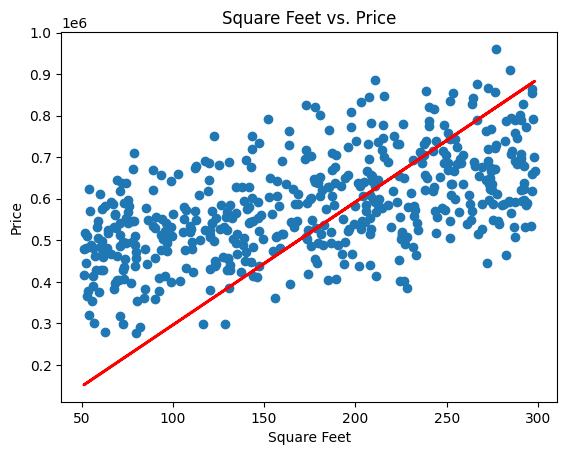

In [28]:
# Plot your data on a scatterplot and draft a regression line. Write your code below.

#Plot points
plt.scatter(df["Square_Feet"], df["Price"])

#Draw the regression line
plt.plot(
    df["Square_Feet"],
    results.predict(),
    color='red',
    linewidth=2,
    label = 'Regression Line'
)

#Add label
plt.title("Square Feet vs. Price")
plt.xlabel("Square Feet")
plt.ylabel("Price")

Ok, let's take it a step further. Our new question is: Does house size still matter when we control for the number of bedrooms and bathrooms?

Fill in the blank: 

The independent variable in this analysis is SQUARE FEET. 

The dependent variable is PRICE. 

The control variables are NUMBER OF BEDROOMS and NUMBER OF BATHROOMS. 

The regression formula is (Price ~ Square_Feet + Num_Bedrooms + Num_Bathrooms). 

I'll help you with the code for the next part.

In [29]:
# Run multiple linear regression
model = smf.ols("Price ~ Square_Feet + Num_Bedrooms + Num_Bathrooms", data=df).fit()

# Display results
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.700
Model:                            OLS   Adj. R-squared:                  0.698
Method:                 Least Squares   F-statistic:                     385.7
Date:                Sat, 07 Nov 2026   Prob (F-statistic):          3.29e-129
Time:                        20:41:50   Log-Likelihood:                -6265.0
No. Observations:                 500   AIC:                         1.254e+04
Df Residuals:                     496   BIC:                         1.255e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept      2.055e+05   1.26e+04     16.270

Fill in the blank: 

Your model explains 70% of the variation in house prices, and all 3 of my 3 explanatory variables are statistically significant.

When square footage is zero, the predicted house price is $205,500.

For every additional square foot, we can expect the predicted house price to increase by $964.615 units, on average.

### Part 2

Read the main article in the Tampa Bay Times' Pulitzer Prize-winning series Failure Factories:\
https://projects.tampabay.com/projects/2015/investigations/pinellas-failure-factories/5-schools-segregation/

And then read the criticism of it in Forbes:\
https://www.forbes.com/sites/maureensullivan/2016/04/29/here-are-the-holes-in-the-pulitzer-winning-failure-factories-series-on-segregated-schools/

Answer the following questions (in at least 3 sentences each), which we will discuss further in class:

1. What are your thoughts on the Tampa Bay Times' series? What parts of it do you find valuable to readers?

2. The series got a scathing critique in Forbes. What are your thoughts on the critique? Do you find it compelling? What do you think the journalists at the Florida newsroom should have done differently? 

1. I thought this piece was surprisngly weak, and even problematic in some parts. There's a conflation between Black students not succeeding schools and high crime levels that is never substantiated or supported with data, and the piece appropriates a derogatory term for an elementary school, "Lil’ Baghdad," without hestiation.

Also, this paragraph about using algorithms to track student risk levels?? And it being presented as an unequivocal good?

    "Broward County created a computer system that assigns a “risk level” to every student based on whether the child has been arrested, suspended, failed a class or referred for social services. Teachers use it to keep tabs on their classes in real time."

And also paragraphs like this where again there is a conflation of low-income/Black students being "bad":

    Resegregating the schools would concentrate the county’s poorest, most challenging students into a handful of south St. Petersburg schools. Teachers would be overwhelmed. Students would stop learning.

I also thought the piece took wayyy too long to actually discuss what racial segregation means in a school district context. I don't know if it's just because this piece was part of a series that gets more in depth, or I'm not used to the constraints print and word limits used to put on pieces, but I feel like the entire story is just a bunch of numbers with very little context, which feels journalistically irresponsible.

At the same time, I think there are benefits to shedding a light on racial segregation in K-12 schools, and I think the piece did a good job of focusing on how the schools were afforded less funding after resegregation occurred. There was an accountability mark that was hit, but there were a lot of strange implicit biases and odd data journalism choices along the way.

2. I think the strongest part of the critique is where it mentions the blogger did a regression holding certain variables as control variables (race,  a proxy for income, and learning disability) and found that only two of the schools were actually performing worse than average based on those factors. That casts a lot of doubt on the claim that the schools and the school board are uniquely bad.

The piece also did a good job pointing out some of the editorializing that happened in the Times piece, which I couldn't tell whether was normal for the time or not.

At the same time, I think this critique seems a little biased itself, in that the author (who served on a school board) seems to have a strong desire to challenge blame placed on the school board, and seems to misunderstand how acts not taken out of racist hate can still have racist consequences, like spuriously increasing racial segregation in a school system.

It seems like both pieces would have been strengthened if the authors thought more about the biases they held entering the writing process, and other factors that may have been influencing their conclusions, whether in a numbers sense or in an argument sense.